# Học phân loại văn bản với dữ liệu tin nhắn SMS spam

Notebook này dạy từng bước: biến văn bản thành số (bag of words, TF-IDF), Naive Bayes, logistic regression cho văn bản, tìm tham số cho cả pipeline xử lý văn bản, đọc từ quan trọng và phân tích lỗi.

Dữ liệu: 5.572 tin nhắn SMS tiếng Anh, mỗi tin có nhãn ham (tin bình thường) hoặc spam (tin rác, quảng cáo, lừa đảo). Nguồn: SMS Spam Collection, UCI (Almeida và Hidalgo, 2011), bản sao trên GitHub của justmarkham.

Chuẩn bị:
1. Đặt file data10.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib scikit-learn

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
pd.set_option('display.max_colwidth', 120)

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào DataFrame và xem vài tin nhắn.

Kiến thức: pd.read_csv đọc file thành bảng. Cột message là văn bản tự do.

Kết quả mong đợi: (5572, 2).

In [2]:
df = pd.read_csv('data10.csv')
print(df.shape)
print(df.head())

(5572, 2)
  label  \
0   ham   
1   ham   
2  spam   
3   ham   
4   ham   

                                                                                                                   message  
0          Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...  
1                                                                                            Ok lar... Joking wif u oni...  
2  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...  
3                                                                        U dun say so early hor... U c already then say...  
4                                                            Nah I don't think he goes to usf, he lives around here though  


## Bước 2: Tỷ lệ spam và tin trùng lặp

Mục tiêu: đếm số tin mỗi loại và số tin bị lặp lại.

Kiến thức: duplicated() đánh dấu các dòng giống hệt một dòng đã xuất hiện trước đó. Tin trùng lặp có thể rơi vào cả tập train và tập test, làm kết quả đánh giá đẹp hơn thực tế.

Kết quả mong đợi: ham có 4825 tin, spam có 747 tin, tỷ lệ spam khoảng 0,134. Có 403 dòng trùng lặp, trong đó 309 ham và 94 spam.

Câu hỏi: có nên xóa tin trùng lặp không? Trong thực tế, tin spam hàng loạt có hay bị gửi lặp lại không?

In [3]:
print(df['label'].value_counts())
print('Tỷ lệ spam:', round((df['label'] == 'spam').mean(), 3))
print('Số dòng trùng lặp:', df.duplicated().sum())
print(df[df.duplicated()]['label'].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64
Tỷ lệ spam: 0.134
Số dòng trùng lặp: 403
label
ham     309
spam     94
Name: count, dtype: int64


## Bước 3: Độ dài tin nhắn

Mục tiêu: tạo feature đơn giản đầu tiên từ văn bản.

Kiến thức: str.len() đếm số ký tự. Một feature đơn giản đôi khi đã phân biệt được hai lớp khá tốt.

Kết quả mong đợi: tin spam dài hơn: trung vị 149 ký tự so với 52 ký tự của ham. Spam tập trung từ 133 đến 157 ký tự, gần giới hạn 160 ký tự của một SMS.

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4825.0   71.5  58.4   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0


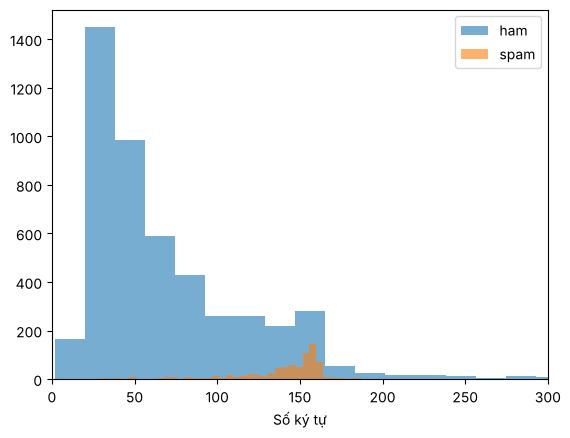

In [4]:
df['length'] = df['message'].str.len()
print(df.groupby('label')['length'].describe().round(1))
for lab in ['ham', 'spam']:
    plt.hist(df.loc[df['label'] == lab, 'length'], bins=50, alpha=0.6, label=lab)
plt.xlim(0, 300)
plt.xlabel('Số ký tự')
plt.legend()
plt.show()

## Bước 4: Chia train/test

Mục tiêu: giữ 20% làm tập test, giữ nguyên tỷ lệ spam.

Kiến thức: y = 1 nếu là spam. X ở bài này là một Series văn bản, không phải bảng số. Bước biến văn bản thành số sẽ được học chỉ từ tập train.

Kết quả mong đợi: X_train có 4457 tin, X_test có 1115 tin (149 spam).

In [5]:
X = df['message']
y = (df['label'] == 'spam').astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(len(X_train), len(X_test), 'spam trong test:', y_test.sum())

4457 1115 spam trong test: 149


## Bước 5: Bag of words

Mục tiêu: biến mỗi tin nhắn thành một vector đếm số lần xuất hiện của từng từ.

Kiến thức: CountVectorizer làm 3 việc: tách văn bản thành từ (tokenize), chuyển về chữ thường, và đếm. Kết quả là một ma trận thưa (sparse matrix): mỗi dòng là một tin, mỗi cột là một từ trong từ điển, phần lớn ô bằng 0. Chỉ fit trên tập train. Từ chưa gặp trong tập test sẽ bị bỏ qua.

Kết quả mong đợi: ma trận train có kích thước (4457, 7668), tức là từ điển có 7668 từ. Chỉ khoảng 0,17% số ô khác 0. Tin đầu tiên 'He will, you guys close?' cho ra 5 từ: he, will, you, guys, close.

Câu hỏi: tại sao lưu dưới dạng ma trận thưa thay vì DataFrame bình thường?

In [6]:
cv = CountVectorizer()
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)
print(X_train_cv.shape, 'số từ:', len(cv.vocabulary_))
print('Tỷ lệ ô khác 0:', round(X_train_cv.nnz / (X_train_cv.shape[0] * X_train_cv.shape[1]), 5))
print(X_train.iloc[0])
print(cv.inverse_transform(X_train_cv[0])[0])

(4457, 7668) số từ: 7668
Tỷ lệ ô khác 0: 0.00172
He will, you guys close?
['he' 'will' 'you' 'guys' 'close']


## Bước 6: Multinomial Naive Bayes

Mục tiêu: huấn luyện mô hình kinh điển cho phân loại văn bản.

Kiến thức: MultinomialNB tính xác suất mỗi từ xuất hiện trong spam và trong ham, rồi dùng định lý Bayes để kết hợp. Nó giả định các từ độc lập với nhau. Giả định này sai, nhưng mô hình vẫn chạy nhanh và thường rất tốt với văn bản. Hàm evaluate dưới đây in các chỉ số cần thiết.

Kết quả mong đợi: accuracy khoảng 0,987, precision khoảng 0,986, recall khoảng 0,919, F1 khoảng 0,951. Có 2 FP và 12 FN.

Câu hỏi: với bộ lọc spam, FP nghĩa là một tin nhắn thật bị đưa vào thư mục spam. FP hay FN gây khó chịu hơn cho người dùng?

In [7]:
def evaluate(name, y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    res = {'Mô hình': name, 'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred),
           'recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred), 'FP': fp, 'FN': fn}
    print(' | '.join(f'{k}: {v:.3f}' if isinstance(v, float) else f'{k}: {v}' for k, v in res.items()))
    return res

nb = MultinomialNB()
nb.fit(X_train_cv, y_train)
pred_nb = nb.predict(X_test_cv)
res_nb = evaluate('NB + count', y_test, pred_nb)

Mô hình: NB + count | accuracy: 0.987 | precision: 0.986 | recall: 0.919 | F1: 0.951 | FP: 2 | FN: 12


## Bước 7: TF-IDF

Mục tiêu: cho từ hiếm và đặc trưng trọng số cao hơn từ phổ biến.

Kiến thức: TF (term frequency) là số lần từ xuất hiện trong tin. IDF (inverse document frequency) lớn khi từ xuất hiện trong ít tin. TF-IDF = TF x IDF, nên từ như "the", "you" có trọng số thấp, còn từ như "prize", "claim" có trọng số cao. TfidfVectorizer còn chuẩn hóa mỗi vector về độ dài 1, nên tin dài và tin ngắn so sánh được với nhau.

Kết quả mong đợi: tin spam đầu tiên là quảng cáo FREE NOKIA. Từ có TF-IDF cao nhất là free (khoảng 0,362), sau đó là các từ hiếm như upto, d3wv, 2price. Các từ có IDF thấp nhất là to, you, the, in, and.

In [8]:
tfidf = TfidfVectorizer()
X_train_tf = tfidf.fit_transform(X_train)
X_test_tf = tfidf.transform(X_test)
words = tfidf.get_feature_names_out()

i = np.where(y_train.values == 1)[0][0]
print(X_train.iloc[i])
row = X_train_tf[i].toarray()[0]
top = row.argsort()[::-1][:5]
print(pd.Series(row[top], index=words[top]).round(3))
print('IDF thấp nhất:', list(words[np.argsort(tfidf.idf_)[:5]]))

FREE NOKIA Or Motorola with upto 12mths 1/2price linerental, 500 FREE x-net mins&100txt/mth FREE B'tooth*. Call Mobileupd8 on 08001950382 or call 2optout/D3WV
free      0.362
upto      0.250
d3wv      0.250
2price    0.250
100txt    0.250
dtype: float64
IDF thấp nhất: ['to', 'you', 'the', 'in', 'and']


## Bước 8: Logistic regression với TF-IDF

Mục tiêu: so sánh logistic regression với Naive Bayes.

Kiến thức: Pipeline gộp TfidfVectorizer và mô hình. Khi đó bạn có thể đưa thẳng văn bản thô vào fit và predict, và cross-validation sẽ fit lại TF-IDF trong từng fold. Logistic regression có tham số C mặc định bằng 1, khá mạnh với văn bản có hàng nghìn cột.

Kết quả mong đợi: accuracy khoảng 0,973, precision bằng 1,0 (không có FP), nhưng recall chỉ khoảng 0,799 (bỏ sót 30 tin spam), F1 khoảng 0,888. Kém NB ở bước 6.

In [9]:
lr = Pipeline([('tfidf', TfidfVectorizer()), ('model', LogisticRegression(max_iter=1000))])
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
res_lr = evaluate('LR + tfidf', y_test, pred_lr)

Mô hình: LR + tfidf | accuracy: 0.973 | precision: 1.000 | recall: 0.799 | F1: 0.888 | FP: 0 | FN: 30


## Bước 9: Tìm tham số cho cả pipeline

Mục tiêu: dùng GridSearchCV để chọn cùng lúc cách tách từ và độ mạnh regularization.

Kiến thức: ngram_range=(1, 2) thêm cặp hai từ liền nhau (bigram) như "free entry", "call now". min_df=2 bỏ các từ chỉ xuất hiện trong 1 tin. Tham số của bước trong pipeline có dạng tên_bước__tên_tham_số. Bước này mất khoảng 30 giây.

Kết quả mong đợi: best params là C = 100, min_df = 1 và ngram_range = (1, 2), CV F1 khoảng 0,95. Trên tập test: recall khoảng 0,906, F1 khoảng 0,944, 2 FP và 14 FN.

In [10]:
param_grid = {'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [1, 2], 'model__C': [1, 10, 100]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(lr, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)
print('best params:', grid.best_params_, '| best CV F1:', round(grid.best_score_, 3))
best = grid.best_estimator_
pred_best = best.predict(X_test)
res_best = evaluate('LR + tfidf tuned', y_test, pred_best)

best params: {'model__C': 100, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)} | best CV F1: 0.95
Mô hình: LR + tfidf tuned | accuracy: 0.986 | precision: 0.985 | recall: 0.906 | F1: 0.944 | FP: 2 | FN: 14


## Bước 10: Từ nào báo hiệu spam

Mục tiêu: đọc hệ số của logistic regression để giải thích mô hình.

Kiến thức: mỗi từ (hoặc cặp từ) có một hệ số. Hệ số dương lớn đẩy tin nhắn về phía spam, hệ số âm đẩy về phía ham.

Kết quả mong đợi: các từ spam mạnh nhất là txt (khoảng 14,4), text, uk, free, call, stop, reply, www, claim. Các từ ham mạnh nhất là my, ok, me, gt, lt, home, sir, da.

Câu hỏi: những từ này có hợp lý không? Kẻ gửi spam có thể né bộ lọc bằng cách nào?

In [11]:
names = best.named_steps['tfidf'].get_feature_names_out()
coef = pd.Series(best.named_steps['model'].coef_[0], index=names).sort_values()
print('Spam:')
print(coef.tail(15)[::-1].round(2))
print('Ham:')
print(coef.head(15).round(2))

Spam:
txt        14.41
text       10.91
uk         10.44
free       10.07
call        9.96
stop        9.94
reply       9.92
www         9.61
to          9.49
claim       9.23
150p        8.32
mobile      8.03
service     7.97
com         7.87
from        7.73
dtype: float64
Ham:
my          -7.91
ok          -7.82
me          -7.55
your call   -7.14
gt          -5.94
lt          -5.88
can         -5.58
ll          -5.51
at          -5.43
home        -5.38
lt gt       -5.35
that        -5.17
sir         -4.80
but         -4.66
da          -4.64
dtype: float64


## Bước 11: Phân tích lỗi

Mục tiêu: đọc các tin nhắn bị phân loại sai để hiểu giới hạn của mô hình.

Kiến thức: lọc X_test theo điều kiện y thật khác y dự đoán. FP là tin ham bị đoán là spam. FN là tin spam bị bỏ sót.

Kết quả mong đợi: có 2 FP, ví dụ 'Alright i have a new goal now'. Có 14 FN, nhiều tin không có từ khóa spam điển hình, ví dụ 'Latest News! Police station toilet stolen...' hoặc tin quảng cáo bán phi tiêu.

In [12]:
errors = pd.DataFrame({'message': X_test, 'thật': y_test, 'đoán': pred_best})
print('FP (ham bị đoán là spam):')
print(errors[(errors['thật'] == 0) & (errors['đoán'] == 1)]['message'].to_string())
print()
print('FN (spam bị bỏ sót):')
print(errors[(errors['thật'] == 1) & (errors['đoán'] == 0)]['message'].to_string())

FP (ham bị đoán là spam):
417               Alright i have a new goal now
700    K..u also dont msg or reply to his msg..

FN (spam bị bỏ sót):
5       FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
3750    Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher call 08704439680. W...
3981                                                                                                         ringtoneking 84484
3360                                             Sorry I missed your call let's talk when you have the time. I'm on 07090201529
5449                                                     Latest News! Police station toilet stolen, cops have nothing to go on!
1460                                          Bought one ringtone and now getting texts costing 3 pound offering more tones etc
1269    Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U c

## Bước 12: Dự đoán tin nhắn mới

Mục tiêu: dùng mô hình cho tin nhắn bạn tự viết.

Kiến thức: vì pipeline chứa cả bước TF-IDF, chỉ cần đưa list văn bản vào predict_proba.

Kết quả mong đợi: hai tin giống spam có xác suất cao (khoảng 1,000 và 0,943). Hai tin bình thường có xác suất rất thấp (khoảng 0,001 và 0,004).

In [13]:
new_msgs = [
    'Congratulations! You have won a free iPhone. Call 09061234567 now to claim your prize',
    'URGENT: your account has been suspended, reply YES to reactivate',
    'Are we still meeting for lunch tomorrow at 12?',
    'Can you send me the slides from today\'s lecture please',
]
for m, p in zip(new_msgs, best.predict_proba(new_msgs)[:, 1]):
    print(f'{p:.3f} | {m}')

1.000 | Congratulations! You have won a free iPhone. Call 09061234567 now to claim your prize
0.943 | URGENT: your account has been suspended, reply YES to reactivate
0.001 | Are we still meeting for lunch tomorrow at 12?
0.004 | Can you send me the slides from today's lecture please


## Bước 13: Bảng so sánh các mô hình

Mục tiêu: ghép kết quả các mô hình vào một bảng.

Kiến thức: thêm một mô hình nữa để so sánh: Naive Bayes với TF-IDF và LinearSVC (SVM tuyến tính, thường rất mạnh với văn bản).

Kết quả mong đợi: NB + count có F1 cao nhất (khoảng 0,951) với 2 FP và 12 FN. LR tuned (F1 khoảng 0,944) và LinearSVC (F1 khoảng 0,941) gần bằng. NB + tfidf có recall thấp nhất (khoảng 0,705) nhưng không có FP nào.

Câu hỏi: mô hình nào bạn sẽ dùng cho bộ lọc spam trên điện thoại? Hãy tính đến cả số FP, không chỉ F1.

In [14]:
nb_tf = Pipeline([('tfidf', TfidfVectorizer()), ('model', MultinomialNB())]).fit(X_train, y_train)
res_nb_tf = evaluate('NB + tfidf', y_test, nb_tf.predict(X_test))
svm = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2))), ('model', LinearSVC())]).fit(X_train, y_train)
res_svm = evaluate('LinearSVC + tfidf', y_test, svm.predict(X_test))
print()
print(pd.DataFrame([res_nb, res_nb_tf, res_lr, res_best, res_svm]).round(3).to_string())

Mô hình: NB + tfidf | accuracy: 0.961 | precision: 1.000 | recall: 0.705 | F1: 0.827 | FP: 0 | FN: 44


Mô hình: LinearSVC + tfidf | accuracy: 0.985 | precision: 0.978 | recall: 0.906 | F1: 0.941 | FP: 3 | FN: 14

             Mô hình  accuracy  precision  recall     F1  FP  FN
0         NB + count     0.987      0.986   0.919  0.951   2  12
1         NB + tfidf     0.961      1.000   0.705  0.827   0  44
2         LR + tfidf     0.973      1.000   0.799  0.888   0  30
3   LR + tfidf tuned     0.986      0.985   0.906  0.944   2  14
4  LinearSVC + tfidf     0.985      0.978   0.906  0.941   3  14


## Bước 14: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Xóa tin trùng lặp (df.drop_duplicates()) trước khi chia train/test, rồi chạy lại mô hình tốt nhất. F1 trên tập test thay đổi thế nào?
2. Thêm stop_words='english' vào TfidfVectorizer. Kết quả tốt hơn hay kém hơn? Vì sao các từ như "you", "your" có thể hữu ích cho việc nhận ra spam?
3. Thử TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5)), tức là dùng cụm ký tự thay vì từ. Cách này có bắt được spam viết sai chính tả như "fr33" không?
4. Viết ba câu tiếng Anh tóm tắt kết quả cho phần "Results" của một báo cáo. Ví dụ: "The tuned logistic regression with word and bigram TF-IDF features reached an F1 score of ... on the test set, with ... false positives."
